In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# INTRODUCTION & VISION


In today's digital landscape, attention is the world's most valuable currency.
 As creator-led enterprises like MrBeast scale to global media empires, audience
 feedback is no longer just casual noise—it's high-stakes market intelligence.
 
 Welcome to our Exploratory Data Analysis (EDA) pipeline. Before training our
 deep learning Transformer (DistilBERT) and (RoBERTa), we must inspect, clean, and decode the
 raw emotional pulse of YouTube viewers to combat class imbalance, eliminate noise,
 and engineer a production-ready sentiment classifier.

In [2]:
import pandas as pd

df = pd.read_csv("sentiment_analysis_dataset.csv", on_bad_lines="warn")
print("Columns:", df.columns.tolist())
print("Row count:", len(df))

Columns: ['Comment', 'Sentiment', 'Unnamed: 2']
Row count: 6821


theme setting for visuals

In [6]:
# Apply seaborn's whitegrid visual theme to plots
sns.set_theme(style="whitegrid")
# Set default font size and automatic layout adjustment for figures
plt.rcParams.update({'font.size': 12, 'figure.autolayout': True})

### 1. LOAD DATASET

In [20]:
dataset_filename = "sentiment_analysis_dataset.csv"

if not os.path.exists(dataset_filename):
  raise FileNotFoundError(
      f"Could not find '{dataset_filename}' in your directory!"
  )

# Load raw dataset, skipping malformed lines
df = pd.read_csv(dataset_filename, on_bad_lines="skip")

# Drop nulls
df.dropna(subset=["Comment", "Sentiment"], inplace=True)


# Filter out broken quote artifacts causing legend bugs
def is_valid_comment(text):
  if not isinstance(text, str):
    return False
  if '"""' in text or text.endswith('""') or text.startswith('""'):
    return False
  return True


df = df[df["Comment"].apply(is_valid_comment)].copy()

# Save permanently to your new clean dataset file
df.to_csv("sentiment_analysis_dataset_clean.csv", index=False)
print(f"✅ Success! Clean dataset saved with {len(df)} valid rows.")

# (Optional: If you want to load from your fresh clean file moving forward)
df = pd.read_csv("sentiment_analysis_dataset_clean.csv")

✅ Success! Clean dataset saved with 6783 valid rows.


C:\Users\Brix Pana\AppData\Local\Temp\ipykernel_20208\3144883455.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


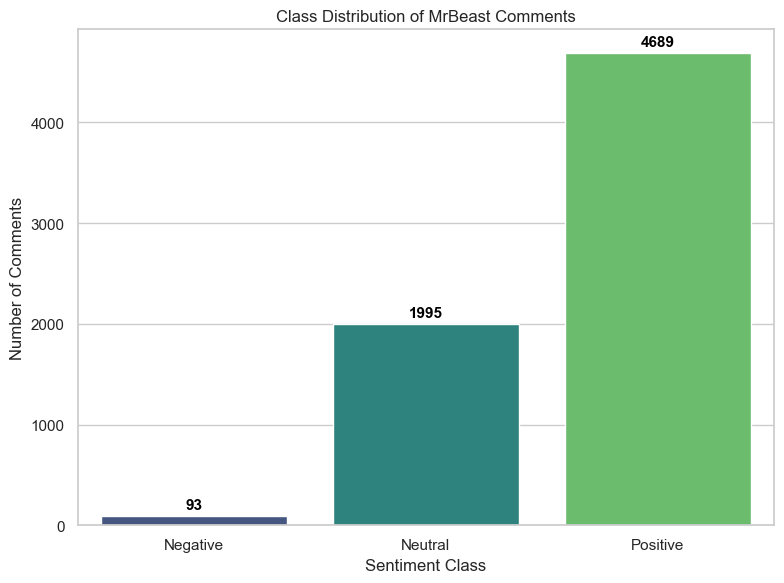

In [21]:
# Ensure output folder exists
os.makedirs("eda_outputs", exist_ok=True)

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 12, "figure.autolayout": True})

# Plot class distribution
plt.figure(figsize=(8, 6))
ax = sns.countplot(
    data=df,
    x="Sentiment",
    order=["Negative", "Neutral", "Positive"],
    palette="viridis",
)
plt.title("Class Distribution of MrBeast Comments")
plt.xlabel("Sentiment Class")
plt.ylabel("Number of Comments")

# Add exact count labels on top of each bar
for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(
        f"{count}",
        (p.get_x() + p.get_width() / 2.0, count),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="black",
        xytext=(0, 3),
        textcoords="offset points",
    )

# Save high-resolution chart and show inline in the notebook
plt.savefig("eda_outputs/class_distribution.png", dpi=300)
plt.show()

## 2. DATA HYGIENE: HANDLE NULLS & DUPLICATES

In [22]:
# Save the row count before dropping missing values
initial_count = len(df)

# Remove rows where 'Comment' or 'Sentiment' is null/NaN
df.dropna(subset=["Comment", "Sentiment"], inplace=True)

# Calculate how many rows were removed due to missing values
nulls_dropped = initial_count - len(df)

# Save the row count right before removing duplicates
before_dedup = len(df)

# Remove duplicate comment texts to avoid bias and train/test leakage
df.drop_duplicates(subset=["Comment"], inplace=True)

# Calculate how many duplicate rows were removed
duplicates_dropped = before_dedup - len(df)

# Print section header for cleaning results
print(f"\n[2] Data Hygiene & Cleaning Results:")
# Print count of removed null rows
print(f"    - Null rows removed: {nulls_dropped}")
# Print count of removed duplicate rows
print(f"    - Duplicate rows removed: {duplicates_dropped}")
# Print remaining unique row count
print(f"    - Final Clean Unique Dataset Rows: {len(df)}")


[2] Data Hygiene & Cleaning Results:
    - Null rows removed: 0
    - Duplicate rows removed: 4956
    - Final Clean Unique Dataset Rows: 1827


### 3. CLASS IMBALANCE ANALYSIS

In [23]:
# Print section header for class distribution
print(f"\n[3] Class Distribution (Sentiment Counts & Ratios):")

# Count how many rows belong to each sentiment class
sentiment_counts = df["Sentiment"].value_counts()

# Calculate each sentiment class as a percentage of the dataset
sentiment_percentages = df["Sentiment"].value_counts(normalize=True) * 100

# Iterate through each sentiment label in descending frequency order
for sentiment in sentiment_counts.index:
    # Print the count and percentage for the current sentiment label
    print(f"    - {sentiment}: {sentiment_counts[sentiment]} comments ({sentiment_percentages[sentiment]:.2f}%)")


[3] Class Distribution (Sentiment Counts & Ratios):
    - Positive: 1260 comments (68.97%)
    - Neutral: 530 comments (29.01%)
    - Negative: 33 comments (1.81%)
    -  you have a shampoo."" then showcases the shiny bald head is crazy": 1 comments (0.05%)
    -  Insane": 1 comments (0.05%)
    -  no brainer"" sm clip that": 1 comments (0.05%)
    -  it comes with a shampoo""": 1 comments (0.05%)


In [24]:
# Filter out rows where comments contain broken or odd quote artifacts
# (e.g., multiple consecutive quotes or weirdly formatted line breaks)
df = df[~df["Comment"].str.contains('""|"\""|„|”', regex=True)].copy()

# Recalculate word counts just to be sure
df["word_count"] = df["Comment"].astype(str).apply(lambda x: len(x.split()))

print(f"Cleaned dataset rows remaining: {len(df)}")

Cleaned dataset rows remaining: 1799


### 4. TEXT LENGTH STATISTICS (Character & Word Counts)

In [25]:
# Compute character length for each comment as a string
df["comment_length"] = df["Comment"].astype(str).apply(len)

# Compute word count by splitting each comment string on whitespace
df["word_count"] = df["Comment"].astype(str).apply(lambda x: len(x.split()))

# Print section header for length statistics
print(f"\n[4] Comment Length & Token Complexity Statistics:")
# Print summary statistics (count, mean, std, min, quartiles, max) for both length columns
print(df[["comment_length", "word_count"]].describe())


[4] Comment Length & Token Complexity Statistics:
       comment_length   word_count
count     1799.000000  1799.000000
mean        45.033352     8.482490
std         30.753912     5.843205
min          1.000000     1.000000
25%         24.000000     4.000000
50%         38.000000     7.000000
75%         59.000000    11.000000
max        294.000000    55.000000


### 5. GENERATE EDA VISUALIZATIONS FOR GITHUB & PRESENTATION SLIDES

Clean sentiments: {'Positive': 1260, 'Neutral': 530, 'Negative': 33}


C:\Users\Brix Pana\AppData\Local\Temp\ipykernel_20208\2824080287.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


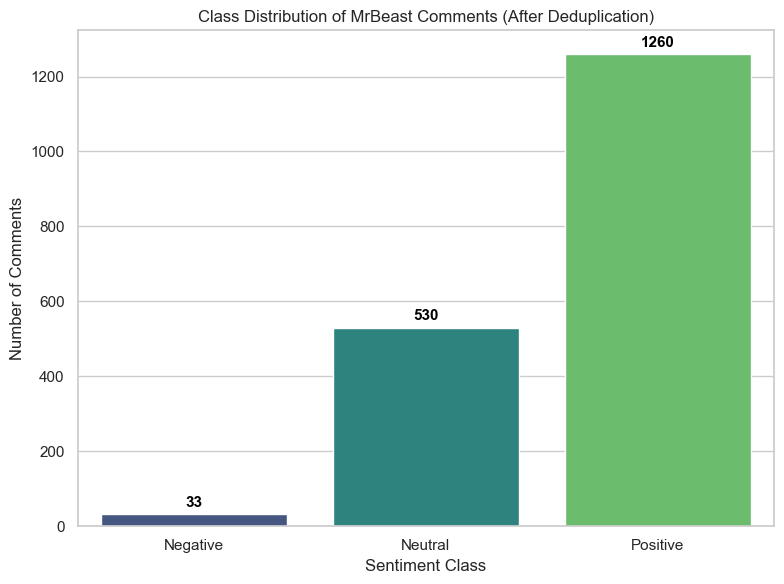

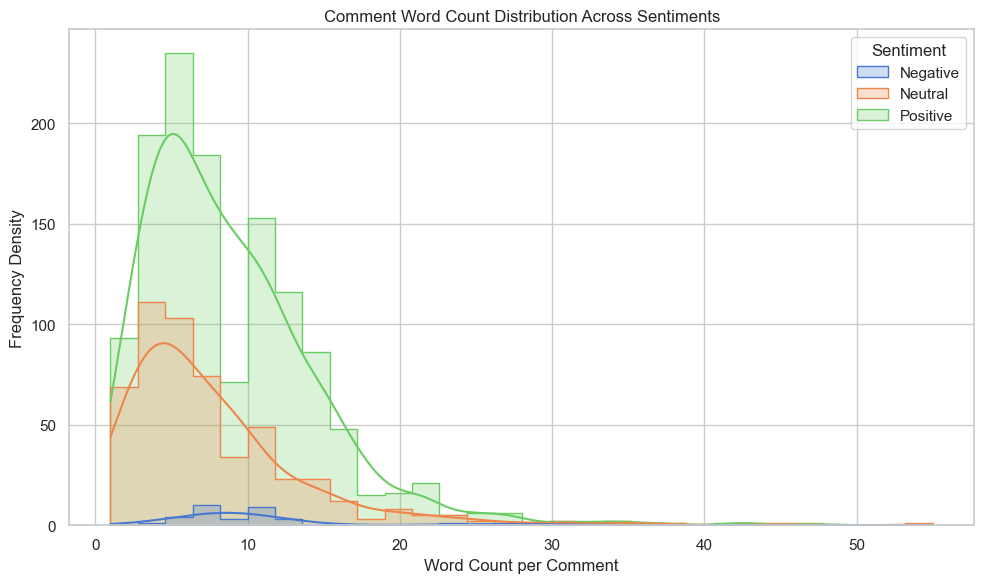

In [33]:
# Define the only allowed sentiment labels
valid_sentiments = ["Negative", "Neutral", "Positive"]

# Load the raw CSV file and skip any corrupted/malformed rows
df = pd.read_csv("sentiment_analysis_dataset.csv", on_bad_lines="skip")
# Drop rows where either Comment or Sentiment is missing (NaN)
df.dropna(subset=["Comment", "Sentiment"], inplace=True)

# Convert Sentiment values to strings and trim leading/trailing spaces
df["Sentiment"] = df["Sentiment"].astype(str).str.strip()
# Keep only rows whose Sentiment matches the three valid labels
df = df[df["Sentiment"].isin(valid_sentiments)].copy()

# Filter out comments containing broken quote patterns (""", leading "", or trailing "")
df = df[
    ~df["Comment"]
    .astype(str)
    .str.contains(r'"""|^""|""$', regex=True, na=False)
]
# Remove duplicate comments so each unique comment appears once
df.drop_duplicates(subset=["Comment"], inplace=True)

# Export the cleaned dataset to a new CSV file without row index numbers
df.to_csv("sentiment_analysis_dataset_clean.csv", index=False)
# Print the final row counts for each sentiment class
print("Clean sentiments:", df["Sentiment"].value_counts().to_dict())

# Compute the word count of each comment for length analysis
df["word_count"] = df["Comment"].astype(str).apply(lambda x: len(x.split()))

# Create the 'eda_outputs' folder if it does not exist yet
os.makedirs("eda_outputs", exist_ok=True)
# Apply Seaborn's clean whitegrid background style
sns.set_theme(style="whitegrid")
# Set global font size to 12 and auto-adjust plot margins
plt.rcParams.update({"font.size": 12, "figure.autolayout": True})

# 1. Class Distribution Chart
# Initialize a new 8x6 inch figure
plt.figure(figsize=(8, 6))
# Draw a bar chart counting comments per sentiment in fixed order
ax = sns.countplot(
    data=df,
    x="Sentiment",
    order=valid_sentiments,
    palette="viridis",
)
# Add chart title and axis labels
plt.title("Class Distribution of MrBeast Comments (After Deduplication)")
plt.xlabel("Sentiment Class")
plt.ylabel("Number of Comments")

# Loop over every bar in the chart to print its exact count above it
for p in ax.patches:
  # Extract the integer height (count) of the current bar
  count = int(p.get_height())
  # Place bold count text centered just above the top of the bar
  ax.annotate(
      f"{count}",
      (p.get_x() + p.get_width() / 2.0, count),
      ha="center",
      va="bottom",
      fontsize=11,
      fontweight="bold",
      color="black",
      xytext=(0, 3),
      textcoords="offset points",
  )

# Save the class distribution chart at 300 DPI
plt.savefig("eda_outputs/class_distribution.png", dpi=300)
# Display the chart inline in the notebook
plt.show()
# Close the figure to free up memory
plt.close()

# 2. Comment Word Count Distribution Chart
# Initialize a new 10x6 inch figure
plt.figure(figsize=(10, 6))
# Plot stepped word-count histograms with smooth KDE curves for each sentiment
sns.histplot(
    data=df,
    x="word_count",
    hue="Sentiment",
    hue_order=valid_sentiments,
    bins=30,
    kde=True,
    palette="muted",
    element="step",
)
# Add chart title and axis labels
plt.title("Comment Word Count Distribution Across Sentiments")
plt.xlabel("Word Count per Comment")
plt.ylabel("Frequency Density")

# Save the word count distribution chart at 300 DPI
plt.savefig("eda_outputs/comment_length_distribution.png", dpi=300)
# Display the chart inline in the notebook
plt.show()
# Close the figure to free up memory
plt.close()